<a href="https://colab.research.google.com/github/KrasheninnikovaOlga/KrasheninnikovaOlga.github.io/blob/master/kids_board_games_recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎲 Kids Board Game Explorer & Recommender

**Which board games are actually worth it for kids — and what should we play next?**

This notebook explores ~20,000 board games from [BoardGameGeek](https://boardgamegeek.com) and builds a small
**content-based recommender** that suggests games for a child's age, the number of players, and the time you have.

**What's inside**
1. Loading & cleaning the BoardGameGeek data
2. Exploration: how kids' games differ from grown-up games
3. Best-rated games by age group
4. Feature engineering: mechanics, categories, description text (TF-IDF), numeric features
5. Unsupervised ML: clustering kids' games into "game types"
6. Recommender #1 — *"We loved X, what's similar?"* (cosine similarity)
7. Recommender #2 — *"My kid is 7, we're 3 players, we have 30 minutes"*
8. Interactive widget to play with recommendations

**Data:** [TidyTuesday 2022-01-25 — Board Games](https://github.com/rfordatascience/tidytuesday/tree/main/data/2022/2022-01-25)
(BoardGameGeek data collected via Kaggle, snapshot from January 2022).

> ▶️ Run all cells: **Runtime → Run all**. No setup or API keys needed.

In [1]:
import ast, html, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler, normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from IPython.display import display

pd.set_option("display.max_colwidth", 60)
ACCENT, GREY, ACCENT2 = "#4C6EF5", "#ADB5BD", "#F59F00"
plt.rcParams.update({
    "figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
})

## 1. Load the data

In [2]:
BASE = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-01-25/"
ratings = pd.read_csv(BASE + "ratings.csv")
details = pd.read_csv(BASE + "details.csv")

raw = ratings.merge(details.drop(columns=["num"]), on="id", how="inner")
print(f"{len(raw):,} games, {raw.shape[1]} columns")
raw[["name", "yearpublished", "minage", "minplayers", "maxplayers", "playingtime",
     "average", "bayes_average", "users_rated"]].head()

21,631 games, 31 columns


,name,yearpublished,minage,minplayers,maxplayers,playingtime,average,bayes_average,users_rated
0,Pandemic,2008,8,2,4,45,7.59,7.487,108975
1,Carcassonne,2000,7,2,5,45,7.42,7.309,108738
2,Catan,1995,10,3,4,120,7.14,6.970,108024
3,7 Wonders,2010,10,2,7,30,7.74,7.634,89982
4,Dominion,2008,13,2,4,30,7.61,7.499,81561


## 2. Clean & prepare

- Categories and mechanics are stored as stringified Python lists → parse them into real lists.
- Descriptions contain HTML entities → unescape and strip.
- Keep games with **at least 200 user ratings** (so ratings are meaningful), a sensible minimum age and play time,
  and drop expansions.
- `bayes_average` is BGG's "geek rating": an average shrunk toward the mean, so a game with 50 perfect votes
  doesn't beat a classic with 50,000 votes. We use it for ranking.

In [3]:
def parse_list(x):
    if not isinstance(x, str):
        return []
    try:
        v = ast.literal_eval(x)
        return [str(i) for i in v] if isinstance(v, (list, tuple)) else []
    except (ValueError, SyntaxError):
        return []

def clean_text(s):
    if not isinstance(s, str):
        return ""
    s = html.unescape(html.unescape(s))
    s = re.sub(r"<[^>]+>", " ", s)
    return re.sub(r"\s+", " ", s).strip()

raw["categories"] = raw["boardgamecategory"].map(parse_list)
raw["mechanics"] = raw["boardgamemechanic"].map(parse_list)
raw["description_clean"] = raw["description"].map(clean_text)

def base_title(name):
    # "Ticket to Ride: Europe" -> "ticket to ride";  "Catan (Junior Edition)" -> "catan"
    return re.split(r"\s*(?:[:(–—]| - )", str(name))[0].strip().lower()

raw["series"] = raw["name"].map(base_title)
raw["implementations"] = raw["boardgameimplementation"].map(parse_list)

# Remove each game's own title from its description, so TF-IDF matches on theme & gameplay words,
# not on the name (otherwise every "Ticket to Ride ..." game looks like every other one)
def strip_title(desc, name, series):
    for t in {str(name), series}:
        if len(t) > 2:
            desc = re.sub(re.escape(t), " ", desc, flags=re.IGNORECASE)
    return desc

raw["description_clean"] = [strip_title(d, n, s) for d, n, s
                            in zip(raw["description_clean"], raw["name"], raw["series"])]

MIN_RATINGS = 200
mask = (
    (raw["users_rated"] >= MIN_RATINGS)
    & (raw["bayes_average"] > 0)
    & raw["minage"].between(2, 18)
    & raw["playingtime"].between(5, 360)
    & (raw["minplayers"] >= 1)
    & (raw["maxplayers"] >= raw["minplayers"])
    & ~raw["categories"].map(lambda c: "Expansion for Base-game" in c)
)
games = raw.loc[mask].copy().reset_index(drop=True)
games["maxplayers"] = games["maxplayers"].clip(upper=12)
games["age_group"] = pd.cut(games["minage"], bins=[0, 5, 7, 9, 11, 99],
                            labels=["2–5", "6–7", "8–9", "10–11", "12+"])
games["kid_friendly"] = games["minage"] <= 8
r = games["bayes_average"]
games["rating_norm"] = (r - r.min()) / (r.max() - r.min())

print(f"{len(games):,} games after cleaning "
      f"({games['kid_friendly'].sum():,} playable from age 8 or younger)")

7,947 games after cleaning (2,374 playable from age 8 or younger)


## 3. Exploration: what do kids' games look like?

,n_games,median_rating,median_time
age_group,,,
2–5,191,5.97,20.0
6–7,506,6.13,20.0
8–9,1817,6.42,30.0
10–11,1866,6.63,45.0
12+,3567,6.97,90.0


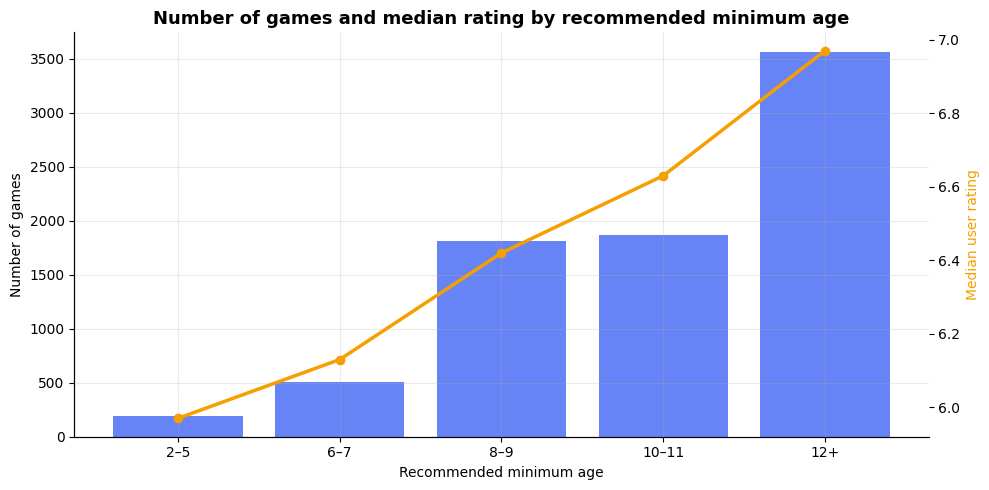

In [4]:
by_age = games.groupby("age_group", observed=True).agg(
    n_games=("id", "size"),
    median_rating=("average", "median"),
    median_time=("playingtime", "median"),
)
display(by_age)

fig, ax = plt.subplots()
ax.bar(by_age.index.astype(str), by_age["n_games"], color=ACCENT, alpha=0.85)
ax.set_xlabel("Recommended minimum age")
ax.set_ylabel("Number of games")
ax2 = ax.twinx()
ax2.plot(by_age.index.astype(str), by_age["median_rating"], color=ACCENT2, marker="o", lw=2.5)
ax2.set_ylabel("Median user rating", color=ACCENT2)
ax2.grid(False); ax2.spines["top"].set_visible(False)
ax.set_title("Number of games and median rating by recommended minimum age")
plt.tight_layout(); plt.show()

> 💡 BGG raters are mostly adult hobbyists, so games for the youngest kids may be rated lower simply because
> grown-ups rate them. That's why below we compare games **within** an age group rather than across all of them.

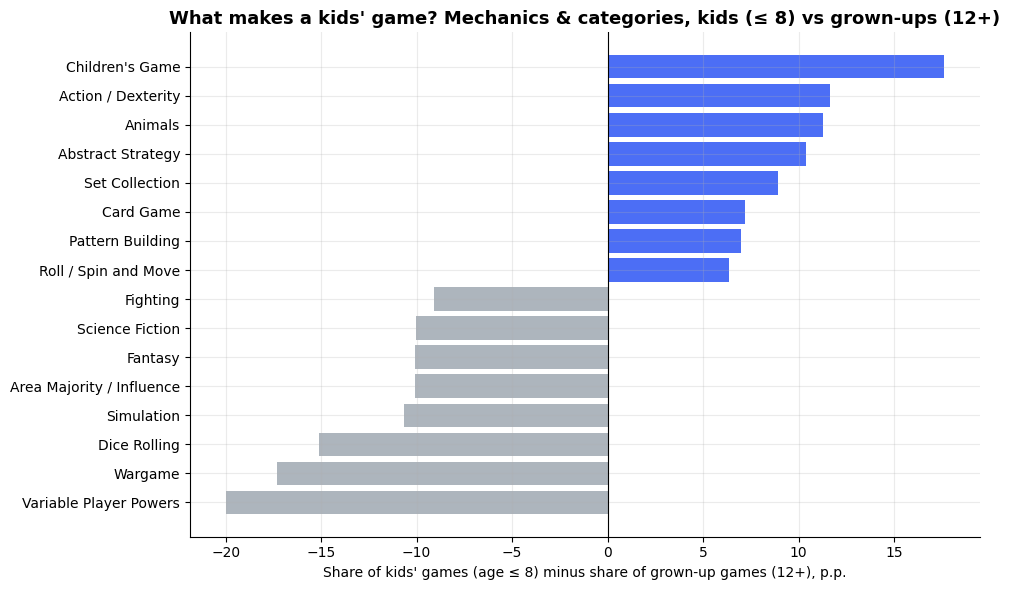

In [5]:
def tag_share(df):
    # a tag like "Memory" can be both a mechanic and a category -> dedupe per game
    tags = (df["mechanics"] + df["categories"]).map(lambda t: sorted(set(t)))
    return tags.explode().value_counts() / len(df)

kids, grownups = games[games["minage"] <= 8], games[games["minage"] >= 12]
diff = tag_share(kids).sub(tag_share(grownups), fill_value=0)
top = pd.concat([diff.nlargest(8), diff.nsmallest(8)]).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top.values * 100, color=[ACCENT if v > 0 else GREY for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Share of kids' games (age ≤ 8) minus share of grown-up games (12+), p.p.")
ax.set_title("What makes a kids' game? Mechanics & categories, kids (≤ 8) vs grown-ups (12+)")
plt.tight_layout(); plt.show()

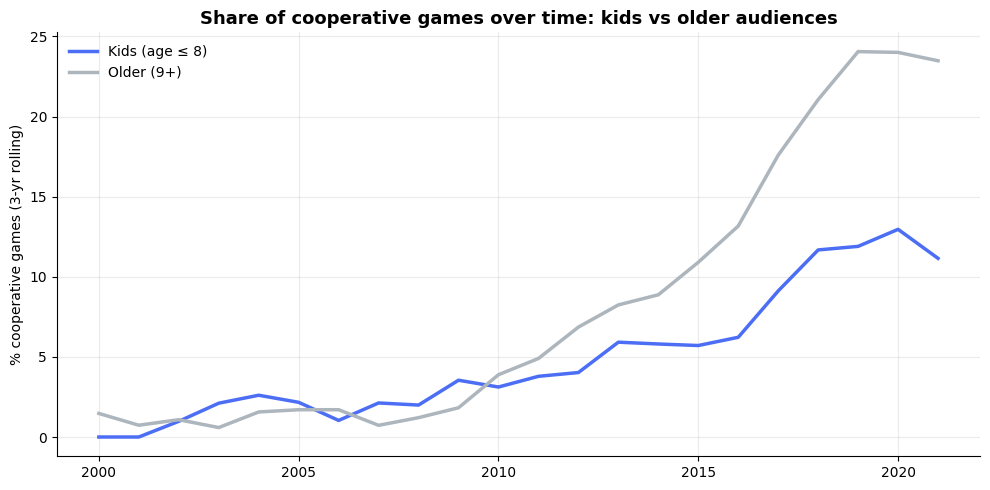

In [6]:
coop = (games[games["yearpublished"].between(2000, 2021)]
        .assign(coop=lambda d: d["mechanics"].map(lambda m: "Cooperative Game" in m),
                segment=lambda d: np.where(d["kid_friendly"], "Kids (age ≤ 8)", "Older (9+)"))
        .groupby(["yearpublished", "segment"])["coop"].mean().unstack()
        .rolling(3, min_periods=1).mean())

fig, ax = plt.subplots()
for col, color in zip(coop.columns, [ACCENT, GREY]):
    ax.plot(coop.index, coop[col] * 100, label=col, color=color, lw=2.5)
ax.set_ylabel("% cooperative games (3-yr rolling)")
ax.set_title("Share of cooperative games over time: kids vs older audiences")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Best-rated games by age group

In [7]:
SHOW = ["name", "yearpublished", "minage", "minplayers", "maxplayers", "playingtime",
        "average", "bayes_average", "users_rated"]

def top_games(age_group, n=10):
    return (games[games["age_group"] == age_group]
            .nlargest(n, "bayes_average")[SHOW].reset_index(drop=True))

for g in ["2–5", "6–7", "8–9", "10–11"]:
    print(f"\n🏆 Top games from age {g}")
    display(top_games(g, 5))


🏆 Top games from age 2–5


,name,yearpublished,minage,minplayers,maxplayers,playingtime,average,bayes_average,users_rated
0,Rhino Hero: Super Battle,2017,5,2,4,20,7.28,6.731,4020
1,Rhino Hero,2011,5,2,5,15,6.94,6.688,9136
2,Animal Upon Animal,2005,4,2,4,15,6.81,6.550,7544
3,Loopin' Louie,1992,4,2,4,10,6.76,6.542,8696
4,Outfoxed!,2014,5,2,4,20,7.19,6.524,2930



🏆 Top games from age 6–7


,name,yearpublished,minage,minplayers,maxplayers,playingtime,average,bayes_average,users_rated
0,Carcassonne,2000,7,2,5,45,7.42,7.309,108738
1,Mice and Mystics,2012,7,1,4,90,7.29,7.057,17612
2,PitchCar,1995,6,2,8,30,7.27,6.999,10023
3,Stuffed Fables,2018,7,2,4,90,7.53,6.975,5398
4,Zombie Kidz Evolution,2018,7,2,4,15,7.82,6.899,2904



🏆 Top games from age 8–9


,name,yearpublished,minage,minplayers,maxplayers,playingtime,average,bayes_average,users_rated
0,Azul,2017,8,2,4,45,7.80,7.686,62802
1,Crokinole,1876,8,2,4,30,7.95,7.672,13453
2,Patchwork,2014,8,2,2,30,7.64,7.535,52190
3,The Isle of Cats,2019,8,1,4,90,7.92,7.529,11116
4,Pandemic,2008,8,2,4,45,7.59,7.487,108975



🏆 Top games from age 10–11


,name,yearpublished,minage,minplayers,maxplayers,playingtime,average,bayes_average,users_rated
0,7 Wonders Duel,2015,10,2,2,30,8.11,7.984,69472
1,Wingspan,2019,10,1,5,70,8.10,7.944,56079
2,Root,2018,10,2,4,90,8.10,7.885,31553
3,The Crew: The Quest for Planet Nine,2019,10,2,5,20,7.97,7.778,24972
4,The Quacks of Quedlinburg,2018,10,2,4,45,7.85,7.678,29635


## 5. Feature engineering for ML

Each game becomes a vector built from four blocks:

| Block | How | Captures |
|---|---|---|
| Mechanics | multi-hot (`MultiLabelBinarizer`) | *how* you play: cooperative, dice, memory, drafting… |
| Categories | multi-hot | *what it's about*: animals, educational, fantasy… |
| Description | TF-IDF on unigrams + bigrams | theme & vocabulary ("dragons", "pirates", "spelling") |
| Numeric | standardized min age, players, log play time | how heavy / long the game is |

Each block is L2-normalized and weighted, so no single block dominates. Then **cosine similarity**
between vectors = how similar two games are.

In [8]:
W = {"mechanics": 1.0, "categories": 1.0, "text": 0.7, "numeric": 0.5}

mlb_mech = MultiLabelBinarizer(sparse_output=True)
mlb_cat = MultiLabelBinarizer(sparse_output=True)
X_mech = mlb_mech.fit_transform(games["mechanics"]).astype(float)
X_cat = mlb_cat.fit_transform(games["categories"]).astype(float)

tfidf = TfidfVectorizer(max_features=6000, stop_words="english", min_df=5,
                        ngram_range=(1, 2), sublinear_tf=True)
X_text = tfidf.fit_transform(games["description_clean"])

num = games[["minage", "minplayers", "maxplayers"]].assign(
    log_time=np.log1p(games["playingtime"]))
X_num = sparse.csr_matrix(StandardScaler().fit_transform(num) / np.sqrt(num.shape[1]))

X = sparse.hstack([
    normalize(X_mech) * W["mechanics"],
    normalize(X_cat) * W["categories"],
    normalize(X_text) * W["text"],
    X_num * W["numeric"],
]).tocsr()
X = normalize(X)

print(f"Feature matrix: {X.shape[0]:,} games × {X.shape[1]:,} features "
      f"({len(mlb_mech.classes_)} mechanics, {len(mlb_cat.classes_)} categories, "
      f"{len(tfidf.vocabulary_)} text terms)")

Feature matrix: 7,947 games × 6,268 features (182 mechanics, 82 categories, 6000 text terms)


## 6. Unsupervised ML: what *types* of kids' games exist?

Clustering kids' games (age ≤ 10): reduce the feature matrix with **TruncatedSVD**,
group games with **K-Means**, and name each cluster by the tags that are most over-represented in it.
**t-SNE** gives a 2-D map for the picture.

In [9]:
K = 8
kid_idx = np.where(games["minage"] <= 10)[0]
Z = normalize(TruncatedSVD(n_components=40, random_state=42).fit_transform(X[kid_idx]))
labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Z)

kid_games = games.iloc[kid_idx].copy()
kid_games["cluster"] = labels
kid_games["tags"] = (kid_games["mechanics"] + kid_games["categories"]).map(lambda t: sorted(set(t)))

overall = kid_games.explode("tags")["tags"].value_counts() / len(kid_games)
def cluster_name(df):
    share = df.explode("tags")["tags"].value_counts() / len(df)
    lift = (share / overall.reindex(share.index))[share >= 0.25]
    return " · ".join(lift.nlargest(3).index)

summary = (kid_games.groupby("cluster")[["tags", "name", "bayes_average"]]
           .apply(lambda d: pd.Series({
               "name": cluster_name(d),
               "n_games": len(d),
               "examples": ", ".join(d.nlargest(3, "bayes_average")["name"]),
           }))
           .sort_values("n_games", ascending=False))
display(summary)

,name,n_games,examples
cluster,,,
1,Hand Management · Card Game · Set Collection,783,"Wingspan, The Crew: The Quest for Planet Nine, 7 Wonders"
4,Economic · Tile Placement · Set Collection,722,"The Isle of Cats, Pandemic: Iberia, PARKS"
3,Fighting · Variable Player Powers · Modular Board,617,"Root, The Quacks of Quedlinburg, Champions of Midgard"
7,Card Game · Set Collection,549,"7 Wonders Duel, The Crew: Mission Deep Sea, Splendor"
0,Children's Game · Action / Dexterity,493,"Crokinole, KLASK, PitchCar"
5,Dice · Dice Rolling · Push Your Luck,419,"Stone Age, That's Pretty Clever!, Roll Player"
2,Abstract Strategy · Pattern Building · Tile Placement,390,"Azul, Patchwork, Azul: Summer Pavilion"
6,Party Game · Deduction · Bluffing,367,"Welcome To..., Just One, Dixit: Odyssey"


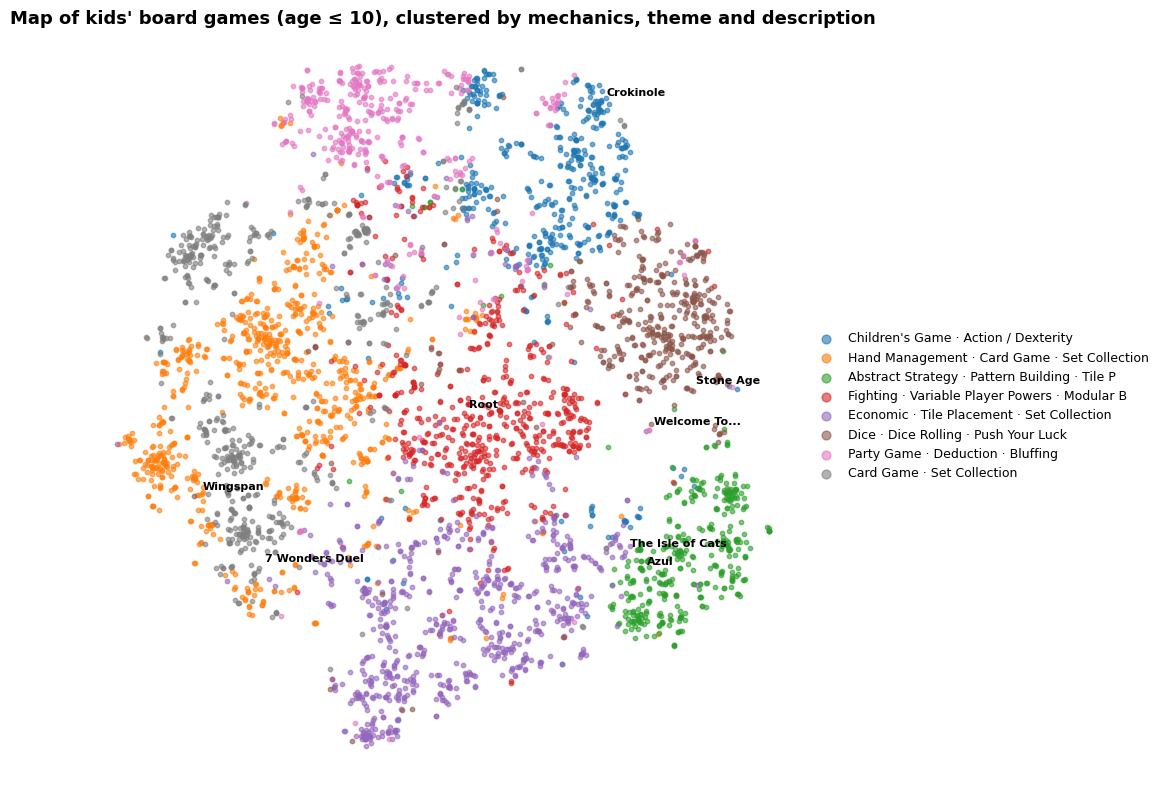

In [10]:
xy = TSNE(n_components=2, init="pca", perplexity=40, random_state=42).fit_transform(Z)
palette = plt.get_cmap("tab10").colors

fig, ax = plt.subplots(figsize=(11, 8))
for c in range(K):
    pts = xy[labels == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.6, color=palette[c % 10],
               label=f"{summary.loc[c, 'name'][:45]}")
# annotate the top-rated game in each cluster
for c in range(K):
    m = labels == c
    best = kid_games["bayes_average"].values[m].argmax()
    x0, y0 = xy[m][best]
    ax.annotate(kid_games["name"].values[m][best], (x0, y0), fontsize=8, weight="bold",
                xytext=(4, 4), textcoords="offset points")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Map of kids' board games (age ≤ 10), clustered by mechanics, theme and description")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=9, markerscale=2)
plt.tight_layout(); plt.show()

## 7. Recommender #1 — "We loved these games. What's similar?"

Content-based recommendation: average the vectors of the games you liked, find the nearest games by cosine
similarity, keep only those suitable for the child's age, and blend similarity with the game's rating
(so a well-loved similar game beats an obscure one).

**Avoiding "same game, different box":** versions and spin-offs (*Ticket to Ride: Europe*, *Catan Junior*) are
obviously similar but useless as recommendations. So we drop games from the same series as the ones you liked
(same base title, or linked as a reimplementation on BGG) and keep at most one game per series in the results.

In [11]:
def same_series(a, b):
    # "catan" vs "catan junior" -> True; very short titles need an exact match
    if a == b:
        return True
    short, long_ = sorted([a, b], key=len)
    return len(short) >= 4 and long_.startswith(short + " ")

def diversify(ranked, n, exclude_series=()):
    # walk down the ranking, keep at most one game per series
    picked, seen = [], list(exclude_series)
    for i, s in zip(ranked.index, ranked["series"]):
        if any(same_series(s, x) for x in seen):
            continue
        picked.append(i); seen.append(s)
        if len(picked) == n:
            break
    return ranked.loc[picked]

def find_game(title):
    t = title.strip().lower()
    exact = games.index[games["name"].str.lower() == t]
    if len(exact):
        return games.loc[exact, "users_rated"].idxmax()
    partial = games.index[games["name"].str.lower().str.contains(re.escape(t), na=False)]
    if len(partial):
        return games.loc[partial, "users_rated"].idxmax()
    raise ValueError(f"Game not found: {title!r}")

def similar_games(liked, max_age=None, n=10, rating_weight=0.3, allow_same_series=False):
    liked = [liked] if isinstance(liked, str) else list(liked)
    idx = [find_game(t) for t in liked]
    profile = normalize(sparse.csr_matrix(X[idx].mean(axis=0)))
    sim = (X @ profile.T).toarray().ravel()
    cand = games.assign(similarity=sim).drop(index=idx)
    if max_age is not None:
        cand = cand[cand["minage"] <= max_age]
    cand = cand.assign(score=(1 - rating_weight) * cand["similarity"]
                             + rating_weight * cand["rating_norm"])
    ranked = cand.sort_values("score", ascending=False)
    if allow_same_series:
        top = ranked.head(n)
    else:
        liked_names = set(games.loc[idx, "name"])
        liked_impl = set().union(*games.loc[idx, "implementations"])
        related = ranked["name"].isin(liked_impl) | ranked["implementations"].map(
            lambda imp: bool(liked_names & set(imp)))
        top = diversify(ranked[~related], n, exclude_series=games.loc[idx, "series"])
    print("Because you liked:", ", ".join(games.loc[idx, "name"]))
    return (top
            [["name", "minage", "minplayers", "maxplayers", "playingtime",
              "bayes_average", "similarity", "score"]]
            .round(3).reset_index(drop=True))

similar_games("Ticket to Ride", max_age=8)

Because you liked: Ticket to Ride


,name,minage,minplayers,maxplayers,playingtime,bayes_average,similarity,score
0,Zug um Zug: Deutschland,8,2,5,60,6.079,0.578,0.556
1,Metro,8,2,6,30,6.154,0.529,0.526
2,Northern Pacific,7,3,6,60,5.967,0.523,0.510
3,On the Underground,7,2,5,60,6.326,0.473,0.497
4,Cable Car,8,2,6,45,5.986,0.502,0.496
5,Trambahn,8,2,2,45,6.288,0.462,0.487
6,Railways of the World: The Card Game,8,2,4,60,5.915,0.488,0.483
7,Continental Express,8,2,4,20,5.615,0.514,0.482
8,Railroad Rivals,8,1,5,60,5.745,0.487,0.472
9,Yardmaster,8,2,5,20,5.874,0.468,0.466


In [12]:
similar_games(["Dixit", "Codenames"], max_age=10)

Because you liked: Dixit, Codenames


,name,minage,minplayers,maxplayers,playingtime,bayes_average,similarity,score
0,Muse,10,2,12,30,6.112,0.633,0.596
1,Detective Club,8,4,8,45,6.560,0.549,0.565
2,Cat & Chocolate,8,3,6,20,5.558,0.615,0.550
3,Sushi Go Party!,8,2,8,20,7.279,0.460,0.547
4,Concept,10,4,12,40,6.656,0.507,0.541
5,Team Work Original,10,4,12,20,5.582,0.594,0.536
6,Just One,8,3,7,20,7.391,0.435,0.536
7,Anomia: Party Edition,10,3,6,30,6.094,0.542,0.532
8,Tem-Purr-A,8,3,10,15,5.665,0.580,0.532
9,When I Dream,8,4,10,40,6.592,0.497,0.531


## 8. Recommender #2 — "My kid is 7, we're 3 players, we have 30 minutes"

Hard filters (age, players, time) + a preference score: what share of the tags you picked
(e.g. *Cooperative Game*, *Animals*, *Memory*) a game has. Each recommendation explains **why** it was picked.

In [13]:
def recommend(age, players, max_time, likes=(), n=10, rating_weight=0.4):
    likes = set(likes)
    cand = games[(games["minage"] <= age)
                 & (games["minplayers"] <= players) & (games["maxplayers"] >= players)
                 & (games["playingtime"] <= max_time)].copy()
    if cand.empty:
        print("No games match these filters — try more time or a different player count.")
        return cand
    tags = cand["mechanics"] + cand["categories"]
    if likes:
        cand["matched"] = tags.map(lambda t: sorted(likes & set(t)))
        cand["pref"] = cand["matched"].map(len) / len(likes)
        cand["score"] = (1 - rating_weight) * cand["pref"] + rating_weight * cand["rating_norm"]
    else:
        cand["matched"], cand["pref"], cand["score"] = [[]] * len(cand), 0.0, cand["rating_norm"]
    cand["why"] = cand["matched"].map(lambda m: ", ".join(m) if m else "highly rated")
    return (diversify(cand.sort_values("score", ascending=False), n)
            [["name", "minage", "minplayers", "maxplayers", "playingtime", "bayes_average", "why"]]
            .round(2).reset_index(drop=True))

recommend(age=7, players=3, max_time=30, likes=["Cooperative Game", "Animals"])

,name,minage,minplayers,maxplayers,playingtime,bayes_average,why
0,Quirky Circuits,7,2,4,30,6.06,"Animals, Cooperative Game"
1,Beasts of Balance,7,1,5,30,5.95,"Animals, Cooperative Game"
2,Concept Kids: Animals,4,2,12,20,5.91,"Animals, Cooperative Game"
3,Mole Rats in Space,7,2,4,20,5.78,"Animals, Cooperative Game"
4,Richard Scarry's Busytown: Eye found it! Game,3,2,4,20,5.74,"Animals, Cooperative Game"
5,Mmm!,5,1,6,20,5.71,"Animals, Cooperative Game"
6,Hoot Owl Hoot!,4,2,4,15,5.71,"Animals, Cooperative Game"
7,The Little Orchard,3,1,4,15,5.69,"Animals, Cooperative Game"
8,Max,4,1,8,20,5.69,"Animals, Cooperative Game"
9,The Ladybug's Costume Party,4,2,6,30,5.68,"Animals, Cooperative Game"


## 9. Try it yourself 👇

In [14]:
import ipywidgets as w

kid_tags = (games[games["minage"] <= 10].assign(t=lambda d: (d["mechanics"] + d["categories"]).map(lambda t: sorted(set(t))))
            .explode("t")["t"].value_counts().head(40).index.tolist())

ui = dict(
    age=w.IntSlider(value=7, min=3, max=14, description="Kid's age"),
    players=w.IntSlider(value=3, min=1, max=8, description="Players"),
    max_time=w.IntSlider(value=30, min=10, max=120, step=5, description="Max minutes"),
    likes=w.SelectMultiple(options=kid_tags, value=("Cooperative Game",), rows=10,
                           description="We like"),
)
out = w.interactive_output(lambda **kw: display(recommend(**kw)), ui)
display(w.HBox([w.VBox([ui["age"], ui["players"], ui["max_time"]]), ui["likes"]]), out)

Output()

In [15]:
# Or start from games you already love:
fav = w.Text(value="Ticket to Ride, Dixit", description="We loved:",
             layout=w.Layout(width="420px"))
age = w.IntSlider(value=8, min=3, max=14, description="Kid's age")
out2 = w.Output()
def run(_=None):
    out2.clear_output()
    with out2:
        try:
            display(similar_games([s for s in fav.value.split(",") if s.strip()], max_age=age.value))
        except ValueError as e:
            print(e)
btn = w.Button(description="Recommend", button_style="primary")
btn.on_click(run)
display(w.HBox([fav, age, btn]), out2)
run()

Output()

## 10. Limitations


**Limitations**
- Data is a January 2022 snapshot; newer games are missing.
- BGG raters are mostly adult hobbyists, so ratings reflect grown-ups' taste more than kids'.
- `minage` is the publisher's recommendation, not a developmental assessment.
- The recommender is **content-based**: it knows what games are *like*, not what similar families enjoyed.

**Next steps**
- Collaborative filtering on user-level ratings (who-liked-what) to complement content similarity.
- Offline evaluation: hold out a user's liked games and measure hit-rate@10.
- Move the pipeline to BigQuery + dbt and refresh it from the BGG API on a schedule.